# 17 — Notebook 15's idle plots again, with the anchor's bursts filtered out

Notebook 16 showed that in the anchored runs one anchor flip flips several targets in the same
shot ("bursts": shots with 2 or more flipped targets), and that these bursts make up most of the
anchored floor and its scatter. Idle dephasing acts on each target separately. This notebook
redraws the two plots of notebook 15 counting only flips from shots with **at most one** flipped
target, i.e. with the burst shots removed.

**Status of this analysis.** The filter was chosen after looking at the shots (notebook 16), so
what follows is exploratory: it says what the existing data look like under the filter, not a
test planned in advance. Two known limits of the filter:
- an anchor flip at the very edge of a coupling sweep flips one target only and is kept, as a
  single flip; such flips do not depend on L, so they raise the floor, not the slope;
- an idle flip that happens in a burst shot is removed with it (≤ 1.4% of shots: negligible).

**Source:** `results/hardware/h2_1e_idle_flip_patterns.json` (`hardware.cli collect`), the
emulator's idle model from `config/h2_1e_emulator.json`; H2-1E via aqora (`q_sq`), one job per
point.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
import math
from scipy.stats import beta, chi2 as chi2_dist
cp = lambda k, n: (beta.ppf(.025, k, n - k + 1) if k else 0.0, beta.ppf(.975, k + 1, n - k))
runs = json.loads((R / "hardware" / "h2_1e_idle_flip_patterns.json").read_text())["runs"]
cal = json.loads((Path("..") / "config" / "h2_1e_emulator.json").read_text())
om = 2 * math.pi * cal["quad_rate"] * cal["quad_factor"]; g = cal["gamma"]
pz = lambda t: g * t + np.sin(om * t / 2) ** 2 - 2 * g * t * np.sin(om * t / 2) ** 2   # emulator idle, t in s
oplus = lambda a, b: a + b - 2 * a * b                                                   # two flip chances

def rates(run):
    """(all flips, flips with burst shots removed) per target sample, with the counts behind them."""
    m = np.array([pat.count("1") for pat, n in run["patterns"].items() for _ in range(n)])
    n_t = len(next(iter(run["patterns"])))
    keep = m <= 1
    return dict(n=len(m), k_all=int(m.sum()), all=m.sum() / (n_t * len(m)),
                kept=int(keep.sum()), k_one=int((m == 1).sum()), one=(m == 1).sum() / (n_t * keep.sum()),
                bursts=int((m >= 2).sum()), n_t=n_t)

def series(design, basis, shots):
    rs = sorted((r for r in runs.values() if r["design"] == design and r["basis"] == basis and r["shots"] == shots),
                key=lambda r: r["layers"])
    return np.array([r["layers"] for r in rs]), [rates(r) for r in rs]

for d in ("measure-and-reset", "transport", "anchored"):
    L, rr = series(d, "X", 100)
    print(f"{d:18s} X, 100 shots: burst shots per run {[r['bursts'] for r in rr]} at L = {L.tolist()}")

measure-and-reset  X, 100 shots: burst shots per run [0, 0, 0, 0, 0, 0, 0] at L = [0, 2, 4, 8, 16, 32, 64]
transport          X, 100 shots: burst shots per run [0, 0, 0, 0, 0] at L = [0, 2, 4, 8, 16]
anchored           X, 100 shots: burst shots per run [1, 1, 1, 0, 3] at L = [0, 2, 4, 8, 16]


## Notebook 15's first plot: three spectator designs, 100 shots each

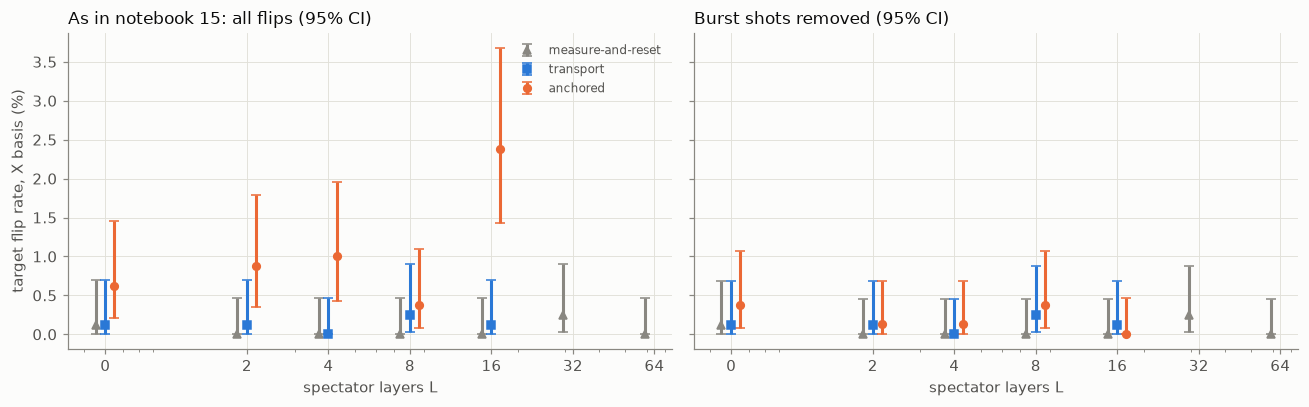

In [3]:
designs = [("measure-and-reset", P.MUTED, "^"), ("transport", P.SERIES[0], "s"), ("anchored", P.SERIES[1], "o")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, key, title in ((axes[0], "all", "As in notebook 15: all flips"),
                       (axes[1], "one", "Burst shots removed")):
    for i, (d, col, mk) in enumerate(designs):
        L, rr = series(d, "X", 100)
        p = np.array([r[key] for r in rr])
        if key == "all":
            ci = np.array([cp(r["k_all"], r["n_t"] * r["n"]) for r in rr]).T
        else:
            ci = np.array([cp(r["k_one"], r["kept"]) for r in rr]).T / 8
        x = np.where(L == 0, 0.6, L) * (0.92 + 0.08 * i)
        ax.errorbar(x, 100 * p, yerr=[100 * (p - ci[0]), 100 * (ci[1] - p)], fmt=mk, color=col, capsize=3, label=d)
    ax.set_xscale("log"); ax.set_xticks([0.6, 2, 4, 8, 16, 32, 64], ["0", "2", "4", "8", "16", "32", "64"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlabel("spectator layers L")
    ax.set_title(title + " (95% CI)", loc="left")
axes[0].set_ylabel("target flip rate, X basis (%)"); axes[0].legend(fontsize=8)
fig.tight_layout()
P.save(fig, "17_idle_from_single_flips_1")

**Reading.**
- *Measured:* removing the burst shots takes the anchored L = 16 point from 2.4% to 0: all 19 of
  its flips were in 3 burst shots. Transport and measure-and-reset do not change (no bursts).
- *Measured:* with bursts removed the three designs agree within their intervals (0–0.4%); the
  anchored floor of notebook 15 was the bursts.
- *Not decidable at 100 shots:* any trend; the intervals span the whole range.

## Notebook 15's second plot: anchored, long waits (1000 shots per X point)

In [4]:
L, rr = series("anchored", "X", 1000)
p = np.array([r["one"] for r in rr]); kept = np.array([r["kept"] for r in rr]); k1 = np.array([r["k_one"] for r in rr])
se = np.sqrt((k1 / kept) * (1 - k1 / kept) / kept) / 8
for l, r in zip(L, rr):
    print(f"X, L = {l:>3}: all flips {100 * r['all']:.2f}%   burst shots removed: {r['k_one']} single flips in "
          f"{r['kept']} shots = {100 * r['one']:.3f}% per target   ({r['bursts']} burst shots removed)")
zr = rates(runs["idleA_Z_L64@500"])
print(f"Z, L =  64: all flips {100 * zr['all']:.2f}%, burst shots removed {100 * zr['one']:.3f}% ({zr['bursts']} burst shots)")

w = 1 / se ** 2; m = (w * p).sum() / w.sum(); c0 = (w * (p - m) ** 2).sum()
print(f"\nconstant {100 * m:.3f}%: chi2 {c0:.1f} on {len(L) - 1} dof, p = {chi2_dist.sf(c0, len(L) - 1):.4f}")

# Emulator idle model on a floor: P(L) = floor (+) pz(tau * L). Fit floor and tau (seconds per layer).
taus = np.linspace(0, 20e-3, 2001); floors = np.linspace(0, 0.006, 601)
best = (np.inf, None, None); prof = []
for t in taus:
    q = pz(t * L)
    c = (w[None, :] * (oplus(floors[:, None], q[None, :]) - p[None, :]) ** 2).sum(axis=1)
    j = int(c.argmin()); prof.append(c[j])
    if c[j] < best[0]: best = (c[j], t, floors[j])
prof = np.array(prof); c1, t1, f1 = best; inside = taus[prof <= c1 + 1]
print(f"emulator idle model: floor {100 * f1:.3f}%, layer {1e3 * t1:.2f} ms "
      f"(68%: {1e3 * inside.min():.2f}-{1e3 * inside.max():.2f} ms), chi2 {c1:.1f} on {len(L) - 2} dof")

# Quantinuum's published H2-1 memory error per depth-1 layer (hardware, not the emulator): 2.0e-4 RB
# infidelity, i.e. a Pauli error of 1.5 x 2.0e-4 per layer, of which 2/3 (Z, Y; depolarising) to all
# (pure Z) flips an X-basis target.
spec = (2 / 3 * 1.5 * 2.0e-4, 1.5 * 2.0e-4)
print(f"published H2-1 memory error, X-basis flips per layer: {spec[0]:.1e}-{spec[1]:.1e}")
slope = np.polyfit(L, p, 1, w=np.sqrt(w))[0]
print(f"straight-line slope of the filtered rate: {slope:.1e} per layer per target")

X, L =   0: all flips 1.03%   burst shots removed: 18 single flips in 985 shots = 0.228% per target   (15 burst shots removed)
X, L =  16: all flips 1.16%   burst shots removed: 25 single flips in 986 shots = 0.317% per target   (14 burst shots removed)
X, L =  32: all flips 1.40%   burst shots removed: 29 single flips in 986 shots = 0.368% per target   (14 burst shots removed)
X, L =  64: all flips 1.50%   burst shots removed: 33 single flips in 980 shots = 0.421% per target   (20 burst shots removed)
X, L = 128: all flips 1.11%   burst shots removed: 50 single flips in 991 shots = 0.631% per target   (9 burst shots removed)
Z, L =  64: all flips 0.45%, burst shots removed 0.450% (0 burst shots)

constant 0.353%: chi2 16.9 on 4 dof, p = 0.0020
emulator idle model: floor 0.284%, layer 1.61 ms (68%: 1.37-1.82 ms), chi2 2.0 on 3 dof
published H2-1 memory error, X-basis flips per layer: 2.0e-04-3.0e-04
straight-line slope of the filtered rate: 3.0e-05 per layer per target


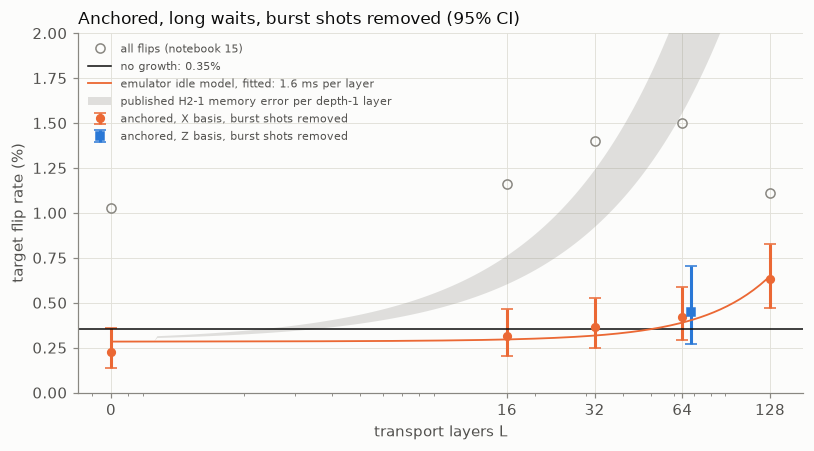

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ci = np.array([cp(int(k), int(n)) for k, n in zip(k1, kept)]).T / 8; x = np.where(L == 0, 0.7, L)
pa = np.array([r["all"] for r in rr])
ax.plot(x, 100 * pa, "o", color=P.MUTED, mfc="none", ms=6, label="all flips (notebook 15)")
ax.errorbar(x, 100 * p, yerr=[100 * (p - ci[0]), 100 * (ci[1] - p)], fmt="o", color=P.SERIES[1], capsize=4,
            label="anchored, X basis, burst shots removed")
zci = np.array(cp(zr["k_one"], zr["kept"])) / 8
ax.errorbar([64 * 1.07], [100 * zr["one"]], yerr=[[100 * (zr["one"] - zci[0])], [100 * (zci[1] - zr["one"])]],
            fmt="s", color=P.SERIES[0], capsize=4, label="anchored, Z basis, burst shots removed")
Ls = np.geomspace(0.7, 128, 200); Lr = np.where(Ls < 1, 0, Ls)
ax.axhline(100 * m, color=P.INK, lw=1, label=f"no growth: {100 * m:.2f}%")
ax.plot(Ls, 100 * oplus(f1, pz(t1 * Lr)), "-", color=P.SERIES[1], lw=1.2,
        label=f"emulator idle model, fitted: {1e3 * t1:.1f} ms per layer")
ax.fill_between(Ls, 100 * oplus(f1, spec[0] * Lr), 100 * oplus(f1, spec[1] * Lr), color=P.MUTED, alpha=0.25, lw=0,
                label="published H2-1 memory error per depth-1 layer")
ax.set_xscale("log"); ax.set_xticks([0.7, 16, 32, 64, 128], ["0", "16", "32", "64", "128"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylim(0, 2); ax.set_xlabel("transport layers L"); ax.set_ylabel("target flip rate (%)"); ax.legend(fontsize=7.5, loc="upper left")
ax.set_title("Anchored, long waits, burst shots removed (95% CI)", loc="left")
fig.tight_layout()
P.save(fig, "17_idle_from_single_flips_2")

**Reading.**
- *Measured:* with the burst shots removed the X-basis rate rises with L, from 0.23% at L = 0
  to 0.63% at L = 128, and a constant no longer fits (printed χ² above). Notebook 15's "no
  consistent growth" came from the pooled rate, in which the bursts (fewest at L = 128) hid this.
- *Measured, against the dephasing reading:* the Z basis at L = 64 (0.45%, no bursts) is as
  high as the X basis at L = 64 (0.42%), and above the 100-shot Z runs at L ≤ 16 (~0.2%). Pure
  dephasing cannot flip a Z-basis target. So either part of the rise is not dephasing (bit
  flips, e.g. from transport or leakage), or the single Z point is high by chance. Z at more
  values of L is needed to tell.
- *Measured:* the emulator's own idle model (Z only) fits the filtered X points with a layer of
  ~1.6 ms (68%: 1.4–1.8 ms). The rise per layer (3e-5) is several times below Quantinuum's
  published H2-1 memory error per depth-1 layer (grey band, 2–3e-4 X-basis flips): the
  emulator's layers are shorter, or its idle noise weaker, than that hardware figure.
- *Exploratory:* the filter was chosen after seeing the data, each point is one job, and the
  slope rests most on L = 128. This changes notebook 15's conclusion from "no idle growth seen"
  to "a growth consistent with idling, seen once, to be confirmed".
- *Next:* a run planned in advance: the same L grid and more shots in **both** bases, counting
  single flips only, with one anchor per target (or the barrier now in Guppy 1.2) so that
  bursts cannot occur.